In [13]:
import ising_2D
import matplotlib.pyplot as plt
import numpy as np

# Qui 1 nmcs = 1 flip

T = np.arange(1, 4, 0.05)
L = 30
nmcs = 900000
nequil = 90000

N_T = len(T)
n_seeds = 10
base_seed = 666
shape = (n_seeds, N_T)

m_all = np.zeros(shape)
m_abs_all = np.zeros(shape)
e_all = np.zeros(shape)
c_all = np.zeros(shape)
chi_all = np.zeros(shape)

for i, t in enumerate(T):
    for s in range(n_seeds):
        ising_2D.set_seed(base_seed + 1000 * i + s)  # unico per (T, seed)
        lattice = ising_2D.initialize_lattice(L, ordered=True)
        M, E, m_avg, m_abs_avg, e_avg, c, chi = ising_2D.evolve(
            lattice, t, nmcs, nequil, bc="periodic", flip_all=False, sequential=True
        )
        m_all[s, i] = m_avg
        m_abs_all[s, i] = m_abs_avg
        e_all[s, i] = e_avg
        c_all[s, i] = c
        chi_all[s, i] = chi

m_avg_arr, err_m_arr = ising_2D.mean_err(m_all)
m_abs_avg_arr, err_m_abs_arr = ising_2D.mean_err(m_abs_all)
e_avg_arr, err_e_arr = ising_2D.mean_err(e_all)
c_arr, err_c_arr = ising_2D.mean_err(c_all)
chi_arr, err_chi_arr = ising_2D.mean_err(chi_all)

# calore specifico dalla derivata: derivata per ogni seed, poi media
c_der_all = np.gradient(e_all, T, axis=1)
c_der_arr, err_c_der_arr = ising_2D.mean_err(c_der_all)

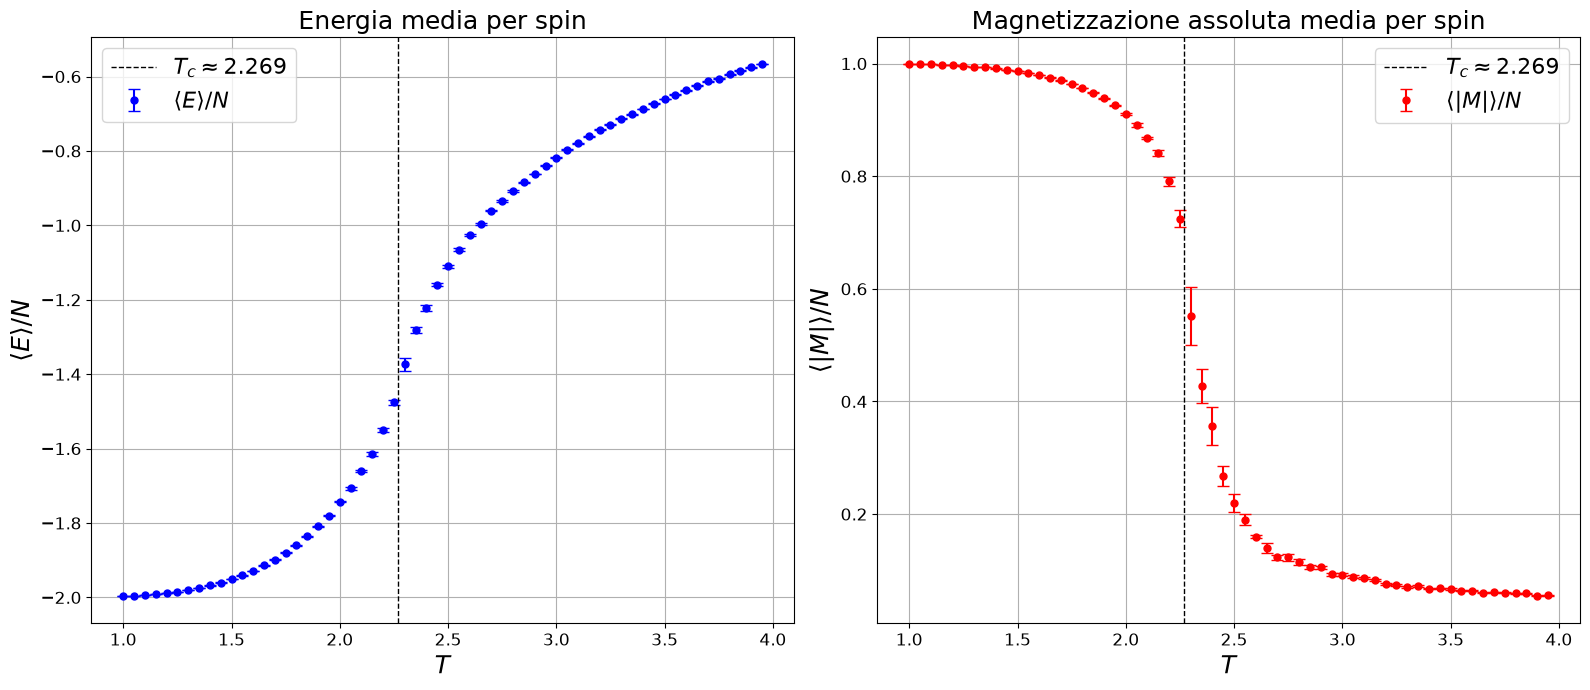

In [15]:
# Plot Punto 1: E/N e M/N con error bars

Tc = 2 / np.log(1 + np.sqrt(2))  # temperatura critica di Onsager (J = kB = 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Plot Energia
ax1.errorbar(
    T,
    e_avg_arr,
    yerr=err_e_arr,
    fmt="o",
    markersize=5,
    capsize=4,
    color="blue",
    label=r"$\langle E \rangle / N$",
)
ax1.axvline(
    Tc, color="black", linestyle="--", linewidth=1, label=r"$T_c \approx 2.269$"
)
ax1.set_xlabel("$T$", fontsize=18)
ax1.set_ylabel(r"$\langle E \rangle / N$", fontsize=18)
ax1.set_title("Energia media per spin", fontsize=18)
ax1.tick_params(axis="both", labelsize=12)
ax1.grid(True)
ax1.legend(fontsize=16)

# Plot Magnetizzazione
ax2.errorbar(
    T,
    m_abs_avg_arr,
    yerr=err_m_abs_arr,
    fmt="o",
    markersize=5,
    capsize=4,
    color="red",
    label=r"$\langle |M| \rangle / N$",
)
ax2.axvline(
    Tc, color="black", linestyle="--", linewidth=1, label=r"$T_c \approx 2.269$"
)
ax2.set_xlabel("$T$", fontsize=18)
ax2.set_ylabel(r"$\langle |M| \rangle / N$", fontsize=18)
ax2.set_title("Magnetizzazione assoluta media per spin", fontsize=18)
ax2.tick_params(axis="both", labelsize=12)
ax2.grid(True)
ax2.legend(fontsize=16)

plt.tight_layout()
plt.savefig(
    "../relazione/images/punto1_energia_magnetizzazione.pdf", bbox_inches="tight"
)
plt.show()

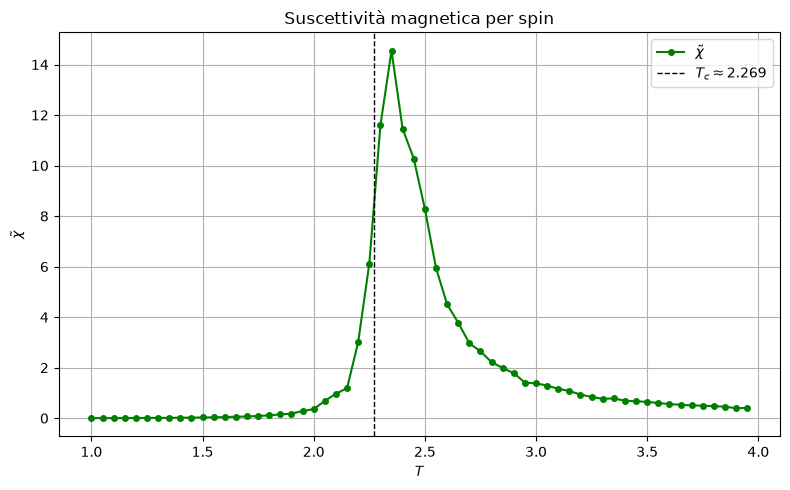

In [3]:
# Plot Punto 2: Suscettività magnetica chi
plt.figure(figsize=(8, 5))

plt.plot(
    T,
    chi_arr,
    marker="o",
    linestyle="-",
    markersize=4,
    color="green",
    label=r"$\tilde{\chi}$",
)
plt.axvline(
    Tc, color="black", linestyle="--", linewidth=1, label=r"$T_c \approx 2.269$"
)
plt.xlabel("$T$")
plt.ylabel(r"$\tilde{\chi}$")
plt.title("Suscettività magnetica per spin")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.savefig("../relazione/images/punto2_chi.pdf")
plt.show()


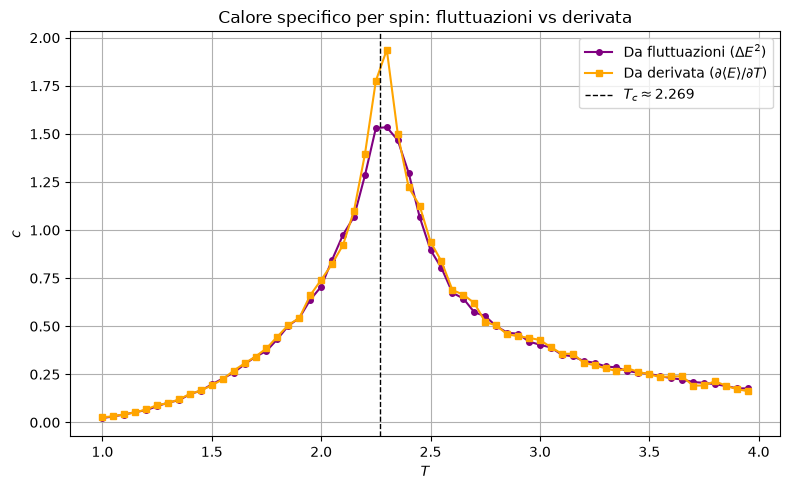

In [4]:
# Plot Punto 3: Calore specifico (Fluttuazioni vs Derivata)

c_deriv = np.gradient(e_avg_arr, T)

plt.figure(figsize=(8, 5))

# c da fluttuazioni di E
plt.plot(
    T,
    c_arr,
    marker="o",
    linestyle="-",
    markersize=4,
    color="purple",
    label=r"Da fluttuazioni ($\Delta E^2$)",
)

# c da derivata numerica
plt.plot(
    T,
    c_deriv,
    marker="s",
    linestyle="-",
    markersize=4,
    color="orange",
    label=r"Da derivata ($\partial \langle E \rangle / \partial T$)",
)

plt.axvline(
    Tc, color="black", linestyle="--", linewidth=1, label=r"$T_c \approx 2.269$"
)
plt.xlabel("$T$")
plt.ylabel("$c$")
plt.title("Calore specifico per spin: fluttuazioni vs derivata")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("../relazione/images/punto3_c.pdf")
plt.show()


In [16]:
# Ora 1 nmcs = L^2 flips

nmcs = 1000
nequil = 200

m_all = np.zeros(shape)
m_abs_all = np.zeros(shape)
e_all = np.zeros(shape)
c_all = np.zeros(shape)
chi_all = np.zeros(shape)

for i, t in enumerate(T):
    for s in range(n_seeds):
        ising_2D.set_seed(base_seed + 1000 * i + s)  # unico per (T, seed)
        lattice = ising_2D.initialize_lattice(L, ordered=True)
        M, E, m_avg, m_abs_avg, e_avg, c, chi = ising_2D.evolve(
            lattice, t, nmcs, nequil, bc="periodic", flip_all=True, sequential=True
        )
        m_all[s, i] = m_avg
        m_abs_all[s, i] = m_abs_avg
        e_all[s, i] = e_avg
        c_all[s, i] = c
        chi_all[s, i] = chi

m_avg_arr, err_m_arr = ising_2D.mean_err(m_all)
m_abs_avg_arr, err_m_abs_arr = ising_2D.mean_err(m_abs_all)
e_avg_arr, err_e_arr = ising_2D.mean_err(e_all)
c_arr, err_c_arr = ising_2D.mean_err(c_all)
chi_arr, err_chi_arr = ising_2D.mean_err(chi_all)

# calore specifico dalla derivata: derivata per ogni seed, poi media
c_der_all = np.gradient(e_all, T, axis=1)
c_der_arr, err_c_der_arr = ising_2D.mean_err(c_der_all)


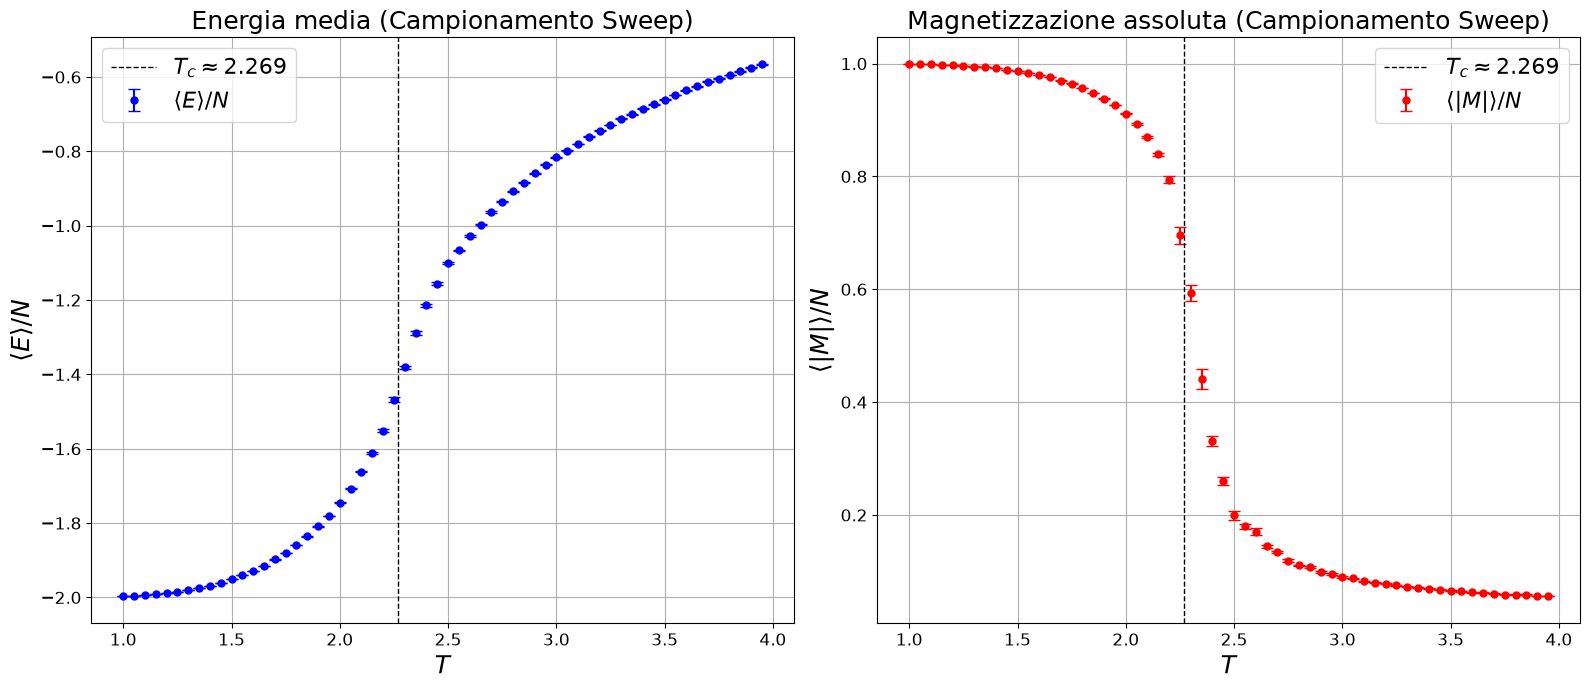

In [18]:
# ==========================================
# Plot Punto 4: E/N e M/N con Sweep (Sweep = N flips)
# ==========================================
fig4, (ax5, ax6) = plt.subplots(1, 2, figsize=(16, 7))

# Energia
ax5.errorbar(
    T,
    e_avg_arr,
    yerr=err_e_arr,
    fmt="o",
    markersize=5,
    capsize=4,
    color="blue",
    label=r"$\langle E \rangle / N$",
)
ax5.axvline(
    Tc, color="black", linestyle="--", linewidth=1, label=r"$T_c \approx 2.269$"
)
ax5.set_xlabel("$T$", fontsize=18)
ax5.set_ylabel(r"$\langle E \rangle / N$", fontsize=18)
ax5.set_title("Energia media (Campionamento Sweep)", fontsize=18)
ax5.tick_params(axis="both", labelsize=12)
ax5.grid(True)
ax5.legend(fontsize=16)

# Magnetizzazione Assoluta
ax6.errorbar(
    T,
    m_abs_avg_arr,
    yerr=err_m_abs_arr,
    fmt="o",
    markersize=5,
    capsize=4,
    color="red",
    label=r"$\langle |M| \rangle / N$",
)
ax6.axvline(
    Tc, color="black", linestyle="--", linewidth=1, label=r"$T_c \approx 2.269$"
)
ax6.set_xlabel("$T$", fontsize=18)
ax6.set_ylabel(r"$\langle |M| \rangle / N$", fontsize=18)
ax6.set_title("Magnetizzazione assoluta (Campionamento Sweep)", fontsize=18)
ax6.tick_params(axis="both", labelsize=12)
ax6.grid(True)
ax6.legend(fontsize=16)

plt.tight_layout()
plt.savefig("../relazione/images/punto4_sweep.pdf", bbox_inches="tight")
plt.show()


In [7]:
# autocorrelazione del calore specifico a T = 2

T = 2

nmcs1 = 900000
nequil1 = 90000
t_max1 = 90000
shape1 = (n_seeds, t_max1)

nmcs2 = 1000
nequil2 = 200
t_max2 = 100
shape2 = (n_seeds, t_max2)

CE1_all = np.zeros(shape1)
CE2_all = np.zeros(shape2)

for s in range(n_seeds):
    ising_2D.set_seed(base_seed + s)

    # 1 flip per passo MC
    lattice1 = ising_2D.initialize_lattice(L, ordered=True)
    M1, E1, m_avg1, m_abs_avg1, e_avg1, c1, chi1 = ising_2D.evolve(
        lattice1, T, nmcs1, nequil1, bc="periodic", flip_all=False, sequential=True
    )

    CE1_all[s] = ising_2D.autocorrelation(E1, t_max1)

    # sweep completo (tutti gli spin) per passo MC
    lattice2 = ising_2D.initialize_lattice(L, ordered=True)
    M2, E2, m_avg2, m_abs_avg2, e_avg2, c2, chi2 = ising_2D.evolve(
        lattice2, T, nmcs2, nequil2, bc="periodic", flip_all=True, sequential=True
    )

    CE2_all[s] = ising_2D.autocorrelation(E2, t_max2)

CE1_avg_arr, CE1_err_arr = ising_2D.mean_err(CE1_all)
CE2_avg_arr, CE2_err_arr = ising_2D.mean_err(CE2_all)

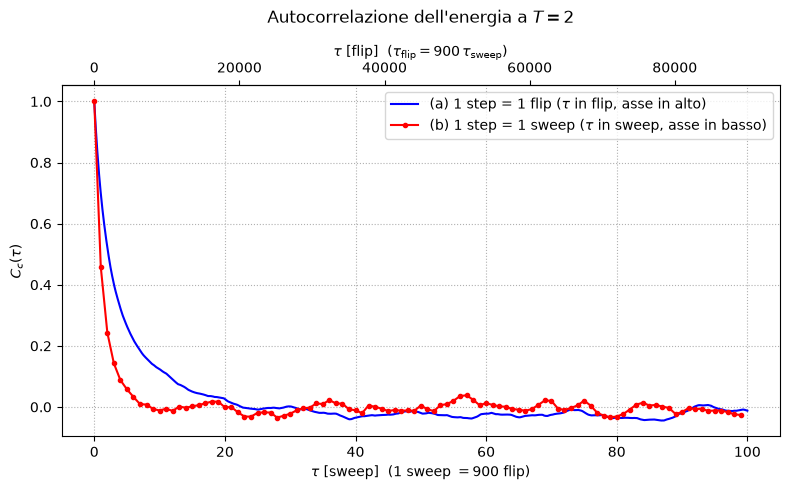

In [10]:
# plot autocorrelazione
fig, ax = plt.subplots(figsize=(8, 5))


Ca = CE1_avg_arr[:90000]
ta = np.arange(len(Ca)) / L**2
ax.plot(
    ta,
    Ca,
    color="blue",
    linewidth=1.5,
    label=r"(a) 1 step = 1 flip ($\tau$ in flip, asse in alto)",
)


Cb = CE2_avg_arr[:100]
tb = np.arange(len(Cb))
ax.plot(
    tb,
    Cb,
    color="red",
    linewidth=1.5,
    marker=".",
    markersize=6,
    label=r"(b) 1 step = 1 sweep ($\tau$ in sweep, asse in basso)",
)

ax.set_xlabel(r"$\tau$ [sweep]  (1 sweep $=900$ flip)")

secax = ax.secondary_xaxis("top", functions=(lambda x: x * L**2, lambda x: x / L**2))
secax.set_xlabel(r"$\tau$ [flip]  ($\tau_{\rm flip} = 900\, \tau_{\rm sweep}$)")

ax.set_ylabel(r"$C_c(\tau)$")
ax.set_title(r"Autocorrelazione dell'energia a $T=2$", pad=45)
ax.grid(True, linestyle=":")
ax.legend()

plt.tight_layout()
plt.savefig("../relazione/images/punto5_autocorrelazione.pdf")
plt.show()


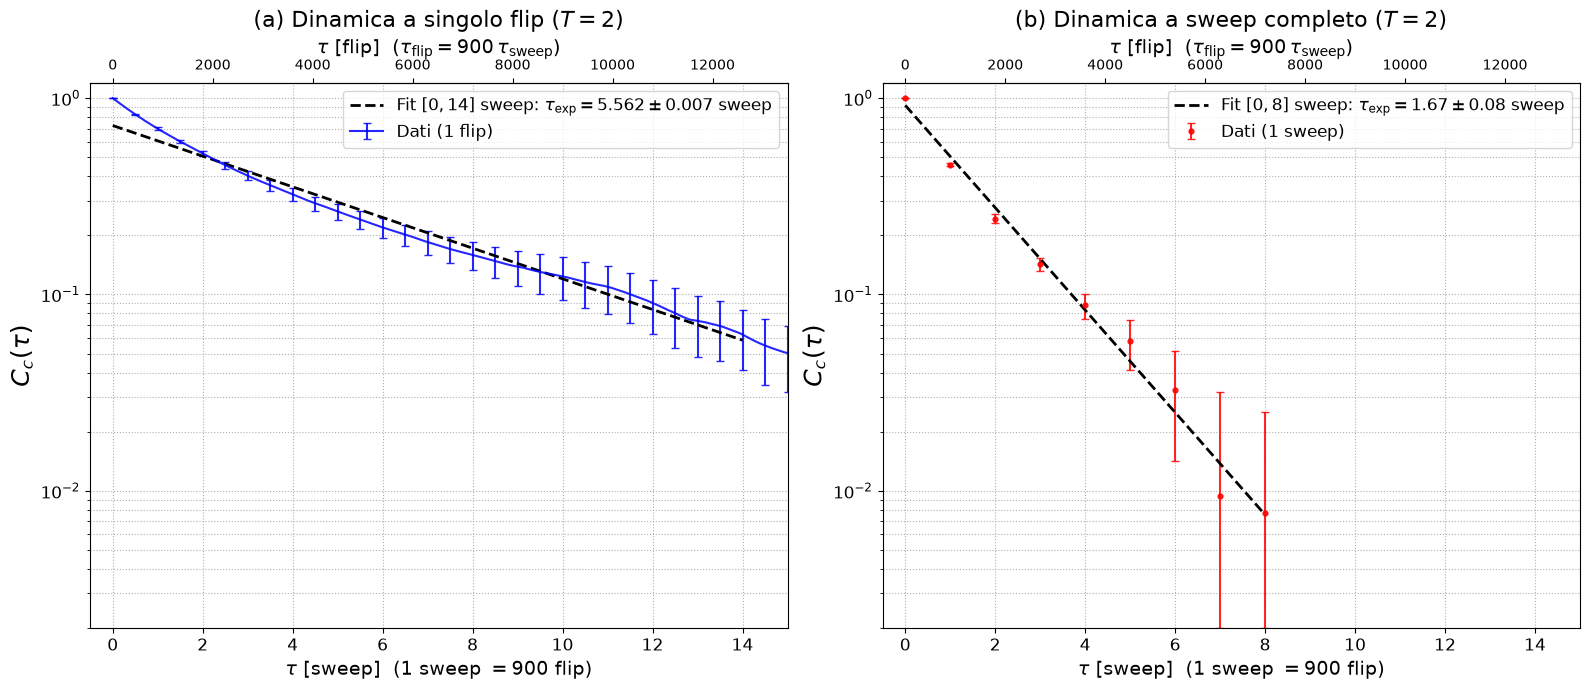

1 flip  -> tau_exp = 5.562 +/- 0.007 sweep (5005.7 +/- 6.0 flip)
1 sweep -> tau_exp = 1.666 +/- 0.075 sweep (1499.2 +/- 67.7 flip)


In [11]:
def fit_tau_exp_unweighted(tau, corr, tau_min, tau_max):
    mask = (tau >= tau_min) & (tau <= tau_max) & (corr > 0)
    t_fit = tau[mask]
    y_fit = np.log(corr[mask])

    (slope, intercept), cov = np.polyfit(t_fit, y_fit, deg=1, cov=True)
    err_slope = np.sqrt(cov[0, 0])

    tau_exp = -1.0 / slope
    err_tau_exp = err_slope / (slope**2)

    return t_fit, np.exp(intercept + slope * t_fit), tau_exp, err_tau_exp


tau_min_a, tau_max_a = 0.0, 14.0
tau_min_b, tau_max_b = 0, 8


Ca = CE1_avg_arr[:90000]
err_Ca = CE1_err_arr[:90000]
ta = np.arange(len(Ca)) / L**2

Cb = CE2_avg_arr[:100]
err_Cb = CE2_err_arr[:100]
tb = np.arange(len(Cb))


t_fit_a, y_fit_a, tau_a, err_tau_a = fit_tau_exp_unweighted(
    ta, Ca, tau_min=tau_min_a, tau_max=tau_max_a
)
t_fit_b, y_fit_b, tau_b, err_tau_b = fit_tau_exp_unweighted(
    tb, Cb, tau_min=tau_min_b, tau_max=tau_max_b
)


fig_fit, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

tau_zoom_max = 15
y_min = 2e-3


mask_a = (ta <= tau_zoom_max) & (Ca >= y_min)
yerr_low_a = np.minimum(err_Ca[mask_a], Ca[mask_a] - y_min * 1.001)

ax1.errorbar(
    ta[mask_a],
    Ca[mask_a],
    yerr=[yerr_low_a, err_Ca[mask_a]],
    errorevery=450,
    fmt="-",
    color="blue",
    linewidth=1.5,
    capsize=3,
    alpha=0.85,
    label="Dati (1 flip)",
)
ax1.plot(
    t_fit_a,
    y_fit_a,
    color="black",
    linestyle="--",
    linewidth=2,
    label=(
        rf"Fit $[{tau_min_a:.0f}, {tau_max_a:.0f}]$ sweep: "
        rf"$\tau_{{\rm exp}} = {tau_a:.3f} \pm {err_tau_a:.3f}$ sweep"
    ),
)

ax1.set_yscale("log")
ax1.set_xlim(-0.5, tau_zoom_max)
ax1.set_ylim(y_min, 1.2)
ax1.set_xlabel(r"$\tau$ [sweep]  (1 sweep $= 900$ flip)", fontsize=14)
secax1 = ax1.secondary_xaxis("top", functions=(lambda x: x * L**2, lambda x: x / L**2))
secax1.set_xlabel(
    r"$\tau$ [flip]  ($\tau_{\rm flip} = 900\, \tau_{\rm sweep}$)", fontsize=14
)
ax1.set_ylabel(r"$C_c(\tau)$", fontsize=18)
ax1.set_title(r"(a) Dinamica a singolo flip ($T=2$)", fontsize=16, pad=40)
ax1.tick_params(axis="both", labelsize=12)
ax1.grid(True, which="both", linestyle=":")
ax1.legend(fontsize=12)

mask_b = (tb <= tau_zoom_max) & (Cb >= y_min)
yerr_low_b = np.minimum(err_Cb[mask_b], Cb[mask_b] - y_min * 1.001)

ax2.errorbar(
    tb[mask_b],
    Cb[mask_b],
    yerr=[yerr_low_b, err_Cb[mask_b]],
    fmt=".",
    color="red",
    markersize=7,
    capsize=3,
    alpha=0.85,
    label="Dati (1 sweep)",
)
ax2.plot(
    t_fit_b,
    y_fit_b,
    color="black",
    linestyle="--",
    linewidth=2,
    label=(
        rf"Fit $[{tau_min_b}, {tau_max_b}]$ sweep: "
        rf"$\tau_{{\rm exp}} = {tau_b:.2f} \pm {err_tau_b:.2f}$ sweep"
    ),
)

ax2.set_yscale("log")
ax2.set_xlim(-0.5, tau_zoom_max)
ax2.set_ylim(y_min, 1.2)
ax2.set_xlabel(r"$\tau$ [sweep]  (1 sweep $= 900$ flip)", fontsize=14)
secax2 = ax2.secondary_xaxis("top", functions=(lambda x: x * L**2, lambda x: x / L**2))
secax2.set_xlabel(
    r"$\tau$ [flip]  ($\tau_{\rm flip} = 900\, \tau_{\rm sweep}$)", fontsize=14
)
ax2.set_ylabel(r"$C_c(\tau)$", fontsize=18)
ax2.set_title(r"(b) Dinamica a sweep completo ($T=2$)", fontsize=16, pad=40)
ax2.tick_params(axis="both", labelsize=12)
ax2.grid(True, which="both", linestyle=":")
ax2.legend(fontsize=12)

plt.tight_layout()
plt.savefig("../relazione/images/punto5_autocorrelazione_fit.pdf", bbox_inches="tight")
plt.show()

print(
    f"1 flip  -> tau_exp = {tau_a:.3f} +/- {err_tau_a:.3f} sweep "
    f"({tau_a * L**2:.1f} +/- {err_tau_a * L**2:.1f} flip)"
)
print(
    f"1 sweep -> tau_exp = {tau_b:.3f} +/- {err_tau_b:.3f} sweep "
    f"({tau_b * L**2:.1f} +/- {err_tau_b * L**2:.1f} flip)"
)
